# One-hidden-layer neural network from scratch: report

MAT0611 "Mathematics for Machine Learning", Albert School.

This report demonstrates `SimpleSLPRegressor` and `SimpleSLPClassifier`, compares them with scikit-learn's
`MLPRegressor` and `MLPClassifier`, and measures the effect of the batch size, early stopping, standardization
and the optimizer.

## 0. Protocol

**Reproducibility.** Every random choice comes from a fixed seed. Each experiment repeats the whole procedure
with the seeds in `SEEDS`, and each seed sets both the train/test split and the model's random state.

**Data.** Each dataset is split into 70% train and 30% test, stratified for classification. Every preprocessing
step (median and mode imputation, `StandardScaler`) is fitted on the training part only, then applied to the test
part, so no information leaks from the test set.

**Metrics.** R² for regression and accuracy for classification. Tables give the mean and standard deviation over
the seeds. Loss curves show the first seed.

**Models compared.** All of them have one hidden layer of 100 neurons and run for at most 200 epochs.

| Name | Settings |
|---|---|
| Mine: defaults | Logistic activation, Adam, `learning_rate=0.001`, `batch_size=32`, `alpha=0` |
| Mine: sklearn-like Adam | ReLU, Adam, `learning_rate=0.001`, `batch_size=min(200, n)`, `alpha=1e-4` |
| sklearn: defaults | `MLPRegressor()` or `MLPClassifier()` |
| Mine: SGD | ReLU, SGD, `learning_rate=0.001`, `batch_size=min(200, n)`, `alpha=0` |
| sklearn: SGD | `solver="sgd"`, `momentum=0`, `alpha=0`, other settings at their defaults |
| Linear baseline | `LinearRegression()` or `LogisticRegression()`, for reference |

"Mine: sklearn-like Adam" and "Mine: SGD" use scikit-learn's settings, so that differences between
implementations are not confused with differences between default settings. One difference remains: scikit-learn
also stops once the training loss stops improving (`tol`), while my models stop this way only with
`early_stopping=True`.

**No selection on the test set.** The analysis reports every setting that was tried. No hyperparameter is chosen
from these test scores, so the tables describe behaviour and do not present a tuned model.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import load_breast_cancer, load_diabetes, load_digits, load_iris
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler

from slp_classifier import SimpleSLPClassifier
from slp_regressor import SimpleSLPRegressor

SEEDS = [42, 43, 44, 45, 46]
TEST_SIZE = 0.3

# scikit-learn warns whenever it reaches max_iter; the epochs columns show this instead.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Colors follow the implementation across all figures. The palette was checked for color vision deficiency.
MINE = "#2a78d6"
SKLEARN = "#eb6834"
MINE_DEFAULTS = "#1baf7a"
BATCH_RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # One hue, from small to large batches
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "figure.dpi": 110,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": "#898781", "ytick.color": "#898781", "xtick.labelcolor": "#52514e", "ytick.labelcolor": "#52514e",
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": "#52514e",
})


def split_and_scale(X, y, seed, task, scale_X=True, scale_y=True):
    """Split the data, then fit the scalers on the training part only."""
    stratify = y if task == "classification" else None
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=seed, stratify=stratify
    )
    if scale_X:
        scaler = StandardScaler().fit(X_train)
        X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)
    if task == "regression" and scale_y:
        scaler = StandardScaler().fit(y_train.reshape(-1, 1))
        y_train = scaler.transform(y_train.reshape(-1, 1)).ravel()
        y_test = scaler.transform(y_test.reshape(-1, 1)).ravel()
    return X_train, X_test, y_train, y_test


def model_configs(task, n_train):
    """Return the models of the protocol, each built from a seed."""
    mine = SimpleSLPRegressor if task == "regression" else SimpleSLPClassifier
    theirs = MLPRegressor if task == "regression" else MLPClassifier
    linear = LinearRegression if task == "regression" else LogisticRegression
    batch = min(200, n_train)
    return {
        "Mine: defaults": lambda s: mine(random_state=s),
        "Mine: sklearn-like Adam": lambda s: mine(activation="relu", batch_size=batch, alpha=1e-4, random_state=s),
        "sklearn: defaults": lambda s: theirs(random_state=s),
        "Mine: SGD": lambda s: mine(activation="relu", solver="sgd", batch_size=batch, random_state=s),
        "sklearn: SGD": lambda s: theirs(solver="sgd", momentum=0.0, alpha=0.0, random_state=s),
        "Linear baseline": lambda s: linear(),
    }


def summarize(rows):
    """Average the per-seed results of each setting."""
    table = pd.DataFrame(rows)
    keys = [c for c in table.columns if c not in ("Train", "Test", "Epochs", "Diverged")]
    agg = table.groupby(keys, sort=False).agg(
        Train=("Train", "mean"), Test=("Test", "mean"), Test_std=("Test", "std"), Epochs=("Epochs", "mean"),
        **({"Diverged": ("Diverged", "sum")} if "Diverged" in table else {}),
    )
    return agg.round({"Train": 3, "Test": 3, "Test_std": 3, "Epochs": 0})


def compare(prepare, task):
    """Train every model of the protocol on every seed."""
    n_train = prepare(SEEDS[0])[0].shape[0]
    rows, curves = [], {}
    for name, build in model_configs(task, n_train).items():
        for seed in SEEDS:
            X_train, X_test, y_train, y_test = prepare(seed)
            model = build(seed).fit(X_train, y_train)
            rows.append({
                "Model": name, "Train": model.score(X_train, y_train), "Test": model.score(X_test, y_test),
                "Epochs": getattr(model, "n_iter_", np.nan) if name != "Linear baseline" else np.nan,
            })
            if seed == SEEDS[0] and hasattr(model, "loss_curve_"):
                curves[name] = model.loss_curve_
    return summarize(rows), curves


def plot_curve(ax, curve, **style):
    """Plot a loss curve, numbering the epochs from 1."""
    ax.plot(np.arange(1, len(curve) + 1), curve, **style)


def plot_curves(curves, title):
    """Loss curves in two panels on one scale: Adam on the left, SGD on the right."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    plot_curve(left, curves["Mine: defaults"], color=MINE_DEFAULTS, label="Mine: defaults")
    plot_curve(left, curves["Mine: sklearn-like Adam"], color=MINE, label="Mine: sklearn-like Adam")
    plot_curve(left, curves["sklearn: defaults"], color=SKLEARN, label="sklearn: defaults")
    plot_curve(right, curves["Mine: SGD"], color=MINE, label="Mine: SGD")
    plot_curve(right, curves["sklearn: SGD"], color=SKLEARN, label="sklearn: SGD")
    left.set_title("Adam", loc="left", fontsize=10)
    right.set_title("SGD, no momentum", loc="left", fontsize=10)
    left.set_ylabel("Training loss")
    for ax, legend_position in ((left, "upper right"), (right, "lower left")):
        ax.set_xlabel("Epoch")
        ax.set_ylim(bottom=0)
        ax.legend(loc=legend_position)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, color="#0b0b0b")
    fig.tight_layout()
    plt.show()

## 1. Regression: `load_diabetes`

442 patients, 10 features, and a target measuring disease progression one year later. `X` and `y` are standardized.

Samples and features: (442, 10), standard deviation of y: 77.0


,Train,Test,Test_std,Epochs
Model,,,,
Mine: defaults,0.542,0.489,0.039,200.0
Mine: sklearn-like Adam,0.698,0.436,0.064,200.0
sklearn: defaults,0.704,0.418,0.061,200.0
Mine: SGD,0.339,0.278,0.089,200.0
sklearn: SGD,0.411,0.345,0.050,200.0
Linear baseline,0.525,0.488,0.037,NaN


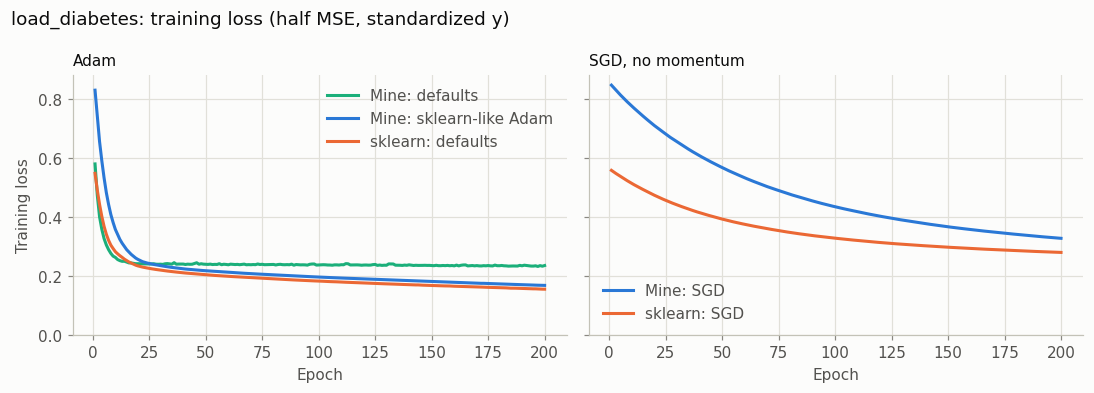

In [2]:
diabetes = load_diabetes()
print(f"Samples and features: {diabetes.data.shape}, standard deviation of y: {diabetes.target.std():.1f}")


def prepare_diabetes(seed):
    return split_and_scale(diabetes.data, diabetes.target, seed, "regression")


diabetes_table, diabetes_curves = compare(prepare_diabetes, "regression")
display(diabetes_table)
plot_curves(diabetes_curves, "load_diabetes: training loss (half MSE, standardized y)")

**Reading the results.**

- With the same settings as scikit-learn's defaults, my model reaches R² = 0.436 against 0.418. With SGD, it reaches
  0.278 against 0.345. Both gaps are smaller than the spread between seeds (0.064 and 0.089).
- My default model reaches 0.489, which is no better than the linear baseline (0.488). With so few samples, a mostly
  linear relationship leaves little for the hidden layer to add.
- The ReLU models overfit: "Mine: sklearn-like Adam" goes from 0.698 on train to 0.436 on test.
- With `learning_rate=0.001` and no momentum, SGD is still improving at epoch 200.

## 2. Binary classification: `load_breast_cancer`

569 tumours, 30 features, 2 classes. `X` is standardized.

Samples and features: (569, 30), share of class 1: 0.627


,Train,Test,Test_std,Epochs
Model,,,,
Mine: defaults,0.992,0.968,0.009,200.0
Mine: sklearn-like Adam,0.993,0.970,0.008,200.0
sklearn: defaults,0.993,0.973,0.008,200.0
Mine: SGD,0.929,0.926,0.021,200.0
sklearn: SGD,0.926,0.937,0.019,200.0
Linear baseline,0.989,0.980,0.010,NaN


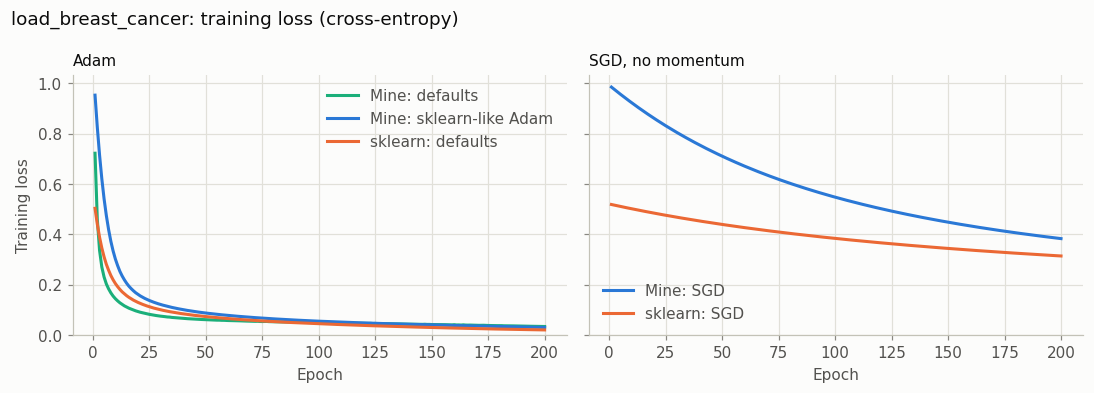

In [3]:
cancer = load_breast_cancer()
print(f"Samples and features: {cancer.data.shape}, share of class 1: {cancer.target.mean():.3f}")


def prepare_cancer(seed):
    return split_and_scale(cancer.data, cancer.target, seed, "classification")


cancer_table, cancer_curves = compare(prepare_cancer, "classification")
display(cancer_table)
plot_curves(cancer_curves, "load_breast_cancer: training loss (cross-entropy)")

**Reading the results.**

- My model and scikit-learn are close: 0.970 against 0.973 with Adam and 0.926 against 0.937 with SGD. Both gaps are
  smaller than the spread between seeds.
- The linear baseline scores highest (0.980): this dataset is close to linearly separable, so a neural network is not
  needed here. The accuracy of 0.968 for my defaults is well above the 0.627 share of the majority class.

## 3. Dataset of my choice: Titanic (Kaggle)

The task is to predict whether a passenger survived, from `Data/titanic/train.csv`.

**Which file.** Kaggle's `test.csv` has no `Survived` column, so it cannot be used to measure accuracy. Its companion
`gender_submission.csv` is not ground truth either: it is simply the rule "women survive". This report therefore uses
only `train.csv`, split as in the protocol.

**Preprocessing**, fitted on the training part only:

| Columns | Treatment | Reason |
|---|---|---|
| `PassengerId`, `Name`, `Ticket` | Dropped | Identifiers, with no direct numeric meaning |
| `Cabin` | Dropped | 77% of the values are missing |
| `Age` | Median imputation | 20% of the values are missing |
| `Embarked` | Most frequent value, then one-hot | 2 missing values |
| `Sex` | One-hot | Categorical |
| `Pclass`, `SibSp`, `Parch`, `Fare` | Kept as numbers | Numeric or ordered |
| All resulting columns | `StandardScaler` | Same scale for every input |

Rows and columns: (891, 12), share of survivors: 0.384


,Share missing
Age,0.199
Cabin,0.771
Embarked,0.002


,Train,Test,Test_std,Epochs
Model,,,,
Mine: defaults,0.807,0.797,0.024,200.0
Mine: sklearn-like Adam,0.850,0.819,0.020,200.0
sklearn: defaults,0.848,0.821,0.018,200.0
Mine: SGD,0.736,0.729,0.056,200.0
sklearn: SGD,0.727,0.716,0.026,200.0
Linear baseline,0.805,0.795,0.029,NaN


Rule 'nobody survives': test accuracy 0.616
Rule 'women survive': test accuracy 0.787


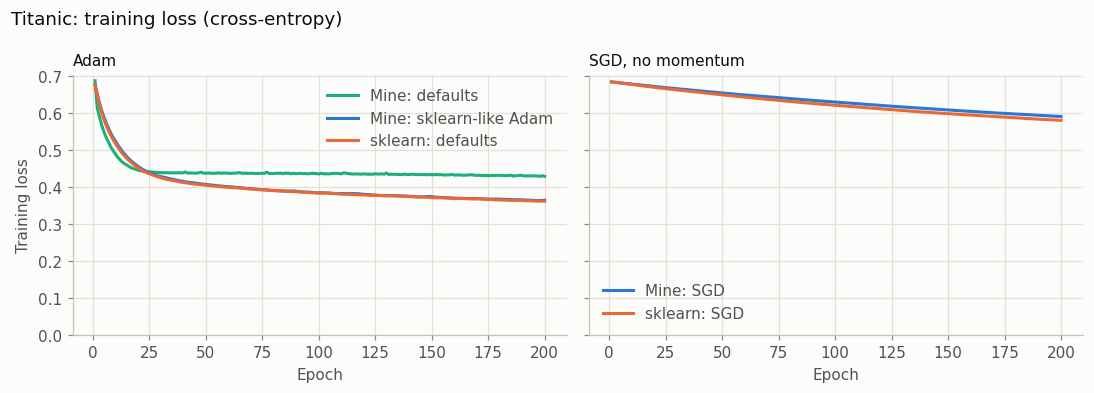

In [4]:
titanic = pd.read_csv("Data/titanic/train.csv")
print(f"Rows and columns: {titanic.shape}, share of survivors: {titanic['Survived'].mean():.3f}")
display(titanic.isna().mean().loc[lambda share: share > 0].round(3).to_frame("Share missing"))


def titanic_features(frame, age_median, embarked_mode):
    """Build the numeric inputs, using values computed on the training part."""
    embarked = frame["Embarked"].fillna(embarked_mode)
    return np.column_stack([
        frame["Pclass"], frame["Age"].fillna(age_median), frame["SibSp"], frame["Parch"], frame["Fare"],
        frame["Sex"] == "male", embarked == "C", embarked == "Q", embarked == "S",
    ]).astype(float)


def prepare_titanic(seed):
    train, test = train_test_split(titanic, test_size=TEST_SIZE, random_state=seed, stratify=titanic["Survived"])
    age_median, embarked_mode = train["Age"].median(), train["Embarked"].mode()[0]
    X_train = titanic_features(train, age_median, embarked_mode)
    X_test = titanic_features(test, age_median, embarked_mode)
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test), train["Survived"].values, test["Survived"].values


titanic_table, titanic_curves = compare(prepare_titanic, "classification")
display(titanic_table)

# Two simple rules give a reference point for these scores.
majority, women = [], []
for seed in SEEDS:
    train, test = train_test_split(titanic, test_size=TEST_SIZE, random_state=seed, stratify=titanic["Survived"])
    majority.append((test["Survived"] == train["Survived"].mode()[0]).mean())
    women.append(((test["Sex"] == "female").astype(int) == test["Survived"]).mean())
print(f"Rule 'nobody survives': test accuracy {np.mean(majority):.3f}")
print(f"Rule 'women survive': test accuracy {np.mean(women):.3f}")
plot_curves(titanic_curves, "Titanic: training loss (cross-entropy)")

**Reading the results.**

- The two simple rules set the bar. Predicting that nobody survives gives 0.616, and predicting that women survive gives
  0.787, which is already close to every model.
- With scikit-learn's settings, my model reaches 0.819 against 0.821. This is the best result on this dataset, about 3
  points above the "women survive" rule and about 2 points above the linear baseline (0.795). The spread between seeds is
  about 2 points, so this gain is modest.
- My default model reaches only 0.797, the same as the linear baseline. The defaults were chosen so that the provided
  tests pass reliably, not to maximize accuracy on this dataset: ReLU does better here.
- The SGD runs are clearly behind (0.729 and 0.716) at `learning_rate=0.001`, and they stay below the "women survive" rule.

## 4. Bonus: multi-class classification

Softmax output on `load_iris` (150 samples, 4 features, 3 classes) and `load_digits` (1797 samples, 64 features,
10 classes). `X` is standardized.

,Train,Test,Test_std,Epochs
Model,,,,
Mine: defaults,0.973,0.933,0.035,200.0
Mine: sklearn-like Adam,0.966,0.938,0.029,200.0
sklearn: defaults,0.966,0.933,0.035,200.0
Mine: SGD,0.642,0.622,0.044,200.0
sklearn: SGD,0.581,0.569,0.127,200.0
Linear baseline,0.971,0.938,0.029,NaN


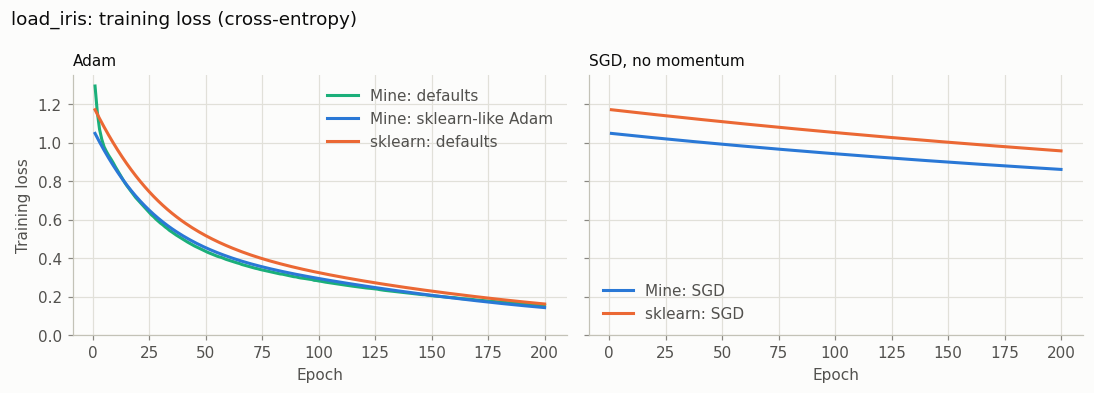

In [5]:
iris = load_iris()


def prepare_iris(seed):
    return split_and_scale(iris.data, iris.target, seed, "classification")


iris_table, iris_curves = compare(prepare_iris, "classification")
display(iris_table)
plot_curves(iris_curves, "load_iris: training loss (cross-entropy)")

,Train,Test,Test_std,Epochs
Model,,,,
Mine: defaults,1.000,0.975,0.003,200.0
Mine: sklearn-like Adam,1.000,0.979,0.004,200.0
sklearn: defaults,1.000,0.978,0.002,149.0
Mine: SGD,0.806,0.792,0.025,200.0
sklearn: SGD,0.805,0.791,0.028,200.0
Linear baseline,0.999,0.970,0.007,NaN


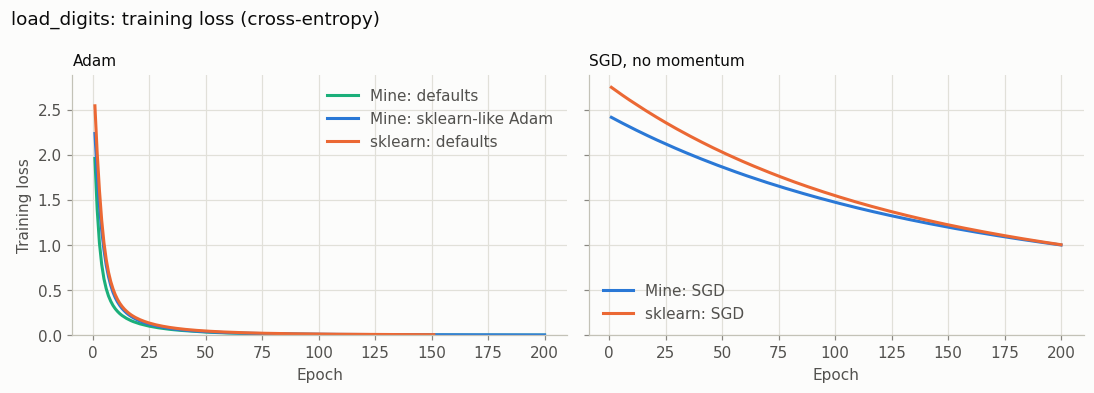

In [6]:
digits = load_digits()


def prepare_digits(seed):
    return split_and_scale(digits.data, digits.target, seed, "classification")


digits_table, digits_curves = compare(prepare_digits, "classification")
display(digits_table)
plot_curves(digits_curves, "load_digits: training loss (cross-entropy)")

**Reading the results.**

- With Adam, my softmax output matches scikit-learn: 0.938 against 0.933 on iris, and 0.979 against 0.978 on digits.
- SGD at `learning_rate=0.001` is far behind in 200 epochs: about 0.6 on iris and 0.79 on digits, for both implementations.
  Its curves are still falling at epoch 200, so this is slow training and not a failure of the softmax.
- On digits, the network (0.979) beats the linear baseline (0.970). On iris, they are tied (0.938).
- scikit-learn stops by itself on digits after 149 epochs on average, thanks to its `tol` criterion.

## 5. Analysis

The four experiments below use my models. Each one changes a single factor and keeps the others fixed.

### 5.1 Effect of the batch size

Adam with the default logistic activation and `learning_rate=0.001`, for 200 epochs.

Train   Test  Test_std  Diverged
Dataset       Batch size                                  
diabetes      8           0.577  0.492     0.031         0
              32          0.542  0.489     0.039         0
              128         0.526  0.486     0.042         0
              full        0.522  0.485     0.039         0
breast cancer 8           1.000  0.964     0.006         0
              32          0.992  0.968     0.009         0
              128         0.988  0.974     0.007         0
              full        0.984  0.975     0.010         0
titanic       8           0.830  0.808     0.029         0
              32          0.807  0.797     0.024         0
              128         0.805  0.796     0.024         0
              full        0.809  0.790     0.026         0
digits        8           1.000  0.977     0.005         0
              32          1.000  0.975     0.003         0
              128         1.000  0.972     0.005         0
              full        0.963  0.948     0.005         0

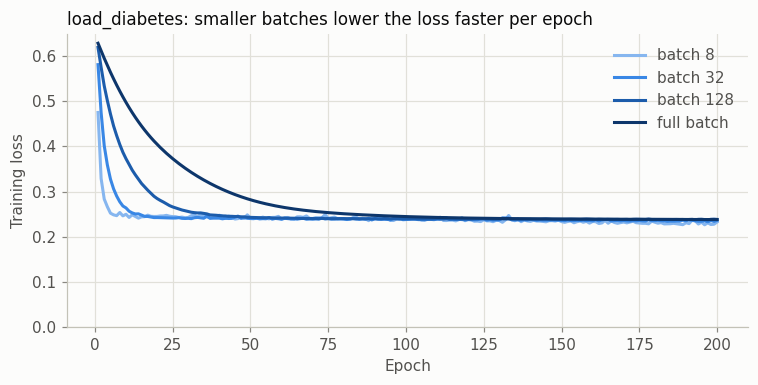

In [7]:
def run(prepare, task, **settings):
    """Train my model with these settings on every seed and return one row per seed."""
    mine = SimpleSLPRegressor if task == "regression" else SimpleSLPClassifier
    rows = []
    for seed in SEEDS:
        X_train, X_test, y_train, y_test = prepare(seed)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)  # Counted in the Diverged column
            model = mine(random_state=seed, **settings).fit(X_train, y_train)
        rows.append({
            "Train": model.score(X_train, y_train), "Test": model.score(X_test, y_test),
            "Epochs": model.n_iter_, "Diverged": int(model.diverged_),
        })
    return rows


DATASETS = {
    "diabetes": (prepare_diabetes, "regression"),
    "breast cancer": (prepare_cancer, "classification"),
    "titanic": (prepare_titanic, "classification"),
    "digits": (prepare_digits, "classification"),
}

rows = []
for dataset, (prepare, task) in DATASETS.items():
    for batch_size in [8, 32, 128, None]:
        label = "full" if batch_size is None else str(batch_size)
        rows += [{"Dataset": dataset, "Batch size": label, **r} for r in run(prepare, task, batch_size=batch_size)]
batch_table = summarize(rows).drop(columns=["Epochs"])
display(batch_table)

X_train, _, y_train, _ = prepare_diabetes(SEEDS[0])
fig, ax = plt.subplots(figsize=(7, 3.6))
for color, batch_size in zip(BATCH_RAMP, [8, 32, 128, None]):
    model = SimpleSLPRegressor(batch_size=batch_size, random_state=SEEDS[0]).fit(X_train, y_train)
    plot_curve(ax, model.loss_curve_, color=color, label="full batch" if batch_size is None else f"batch {batch_size}")
ax.set(xlabel="Epoch", ylabel="Training loss", ylim=(0, None))
ax.set_title("load_diabetes: smaller batches lower the loss faster per epoch", loc="left", fontsize=11)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

**Reading the results.** The effect is clear on the training speed, but much less so on the final test score.

- **Speed per epoch:** a smaller batch makes more updates per epoch, so the loss falls sooner, as the figure shows. On
  `load_diabetes`, all sizes end at about the same loss.
- **Too few updates:** full batch can run out of updates. On digits, it reaches 0.948 against 0.975 at batch size 32, and
  its training score (0.963) shows that training is unfinished.
- **Otherwise, no general winner:** on breast cancer, the test score rises slightly with the batch size (0.964 to 0.975),
  whereas it falls on Titanic (0.808 to 0.790). These gaps are of the same order as the spread between seeds. On diabetes,
  the scores stay within 0.485 to 0.492.

So mini-batches help most when the number of epochs is limited, and the batch size matters less once training has converged.

### 5.2 Effect of early stopping

An oversized network is used on purpose, because that is where overfitting can appear: ReLU, 200 neurons,
`learning_rate=0.01`, up to 500 epochs. Early stopping holds out 10% of the training data.

Train   Test  Test_std  Epochs
Dataset       Early stopping                                
diabetes      False           0.948 -0.023     0.117   500.0
              True            0.586  0.421     0.061    14.0
breast cancer False           1.000  0.970     0.005   500.0
              True            0.993  0.971     0.007    27.0
titanic       False           0.916  0.782     0.022   500.0
              True            0.844  0.806     0.028    19.0
digits        False           1.000  0.983     0.005   500.0
              True            0.998  0.979     0.004    32.0

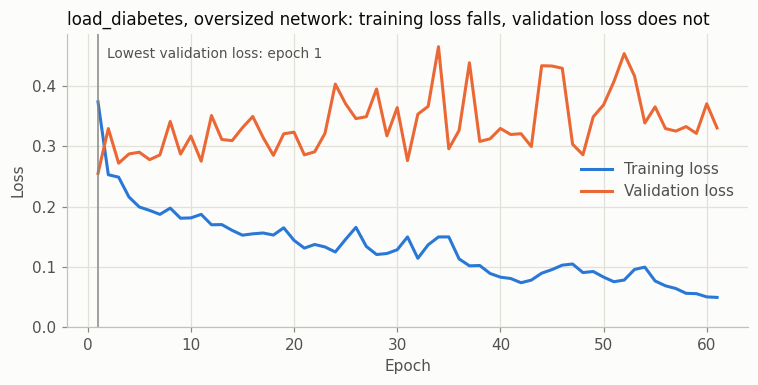

In [8]:
OVERSIZED = dict(hidden_layer_size=200, activation="relu", learning_rate=0.01, max_iter=500)
rows = []
for dataset, (prepare, task) in DATASETS.items():
    for early_stopping in [False, True]:
        rows += [{"Dataset": dataset, "Early stopping": early_stopping, **r}
                 for r in run(prepare, task, early_stopping=early_stopping, **OVERSIZED)]
display(summarize(rows).drop(columns=["Diverged"]))

X_train, _, y_train, _ = prepare_diabetes(SEEDS[0])
model = SimpleSLPRegressor(early_stopping=True, n_iter_no_change=60, random_state=SEEDS[0], **OVERSIZED).fit(X_train, y_train)
best_epoch = int(np.argmin(model.validation_loss_curve_)) + 1  # Epochs are numbered from 1
fig, ax = plt.subplots(figsize=(7, 3.6))
plot_curve(ax, model.loss_curve_, color=MINE, label="Training loss")
plot_curve(ax, model.validation_loss_curve_, color=SKLEARN, label="Validation loss")
ax.axvline(best_epoch, color="#898781", linewidth=1)
ax.annotate(f"Lowest validation loss: epoch {best_epoch}", (best_epoch, ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color="#52514e", fontsize=9)
ax.set(xlabel="Epoch", ylabel="Loss", ylim=(0, None))
ax.set_title("load_diabetes, oversized network: training loss falls, validation loss does not", loc="left", fontsize=11)
ax.legend(loc="center right")
fig.tight_layout()
plt.show()

**Reading the results.** Early stopping prevents overfitting when there is overfitting to prevent. Otherwise, it mainly saves time.

| Dataset | Test score without | Test score with | Epochs without | Epochs with |
|---|---:|---:|---:|---:|
| Diabetes | -0.023 | **0.421** | 500 | 14 |
| Titanic | 0.782 | **0.806** | 500 | 19 |
| Breast cancer | 0.970 | 0.971 | 500 | 27 |
| Digits | 0.983 | 0.979 | 500 | 32 |

- On diabetes, the oversized network without early stopping does worse than predicting the mean (negative R²), with a
  training R² of 0.948.
- On digits, there is little overfitting. Early stopping saves about 94% of the epochs, and costs a small amount of accuracy,
  partly because 10% of the training data is held out.
- For the figure, the patience is raised to 60 epochs to show what happens after the best epoch. For this seed, the lowest
  validation loss comes at the very first epoch, whereas the training loss keeps falling.

### 5.3 Effect of standardization

The two models keep their default settings. "Raw" means that the corresponding scaler is skipped. R² does not depend on
the units of `y`, so the scores remain comparable.

`load_diabetes` needs a remark: scikit-learn already centers its features and scales them to a small norm, so raw `X`
has a standard deviation of about 0.05. Its target, however, is not scaled.

In [9]:
print(f"Standard deviation of raw X: diabetes {diabetes.data.std():.3f}, breast cancer {cancer.data.std():.1f}")
rows = []


def add_standardization_rows(dataset, X, y, task, x_options, y_options):
    mine = SimpleSLPRegressor if task == "regression" else SimpleSLPClassifier
    theirs = MLPRegressor if task == "regression" else MLPClassifier
    for scale_X in x_options:
        for scale_y in y_options:
            for name, build in [("Mine: defaults", mine), ("sklearn: defaults", theirs)]:
                for seed in SEEDS:
                    X_train, X_test, y_train, y_test = split_and_scale(X, y, seed, task, scale_X, scale_y)
                    model = build(random_state=seed).fit(X_train, y_train)
                    rows.append({
                        "Dataset": dataset, "X": "standardized" if scale_X else "raw",
                        "y": "n/a (classes)" if task == "classification" else ("standardized" if scale_y else "raw"),
                        "Model": name,
                        "Train": model.score(X_train, y_train), "Test": model.score(X_test, y_test),
                        "Epochs": model.n_iter_,
                    })


add_standardization_rows("diabetes", diabetes.data, diabetes.target, "regression", [True, False], [True, False])
add_standardization_rows("breast cancer", cancer.data, cancer.target, "classification", [True, False], [True])
display(summarize(rows))

Standard deviation of raw X: diabetes 0.048, breast cancer 228.3


Train   Test  \
Dataset       X            y             Model                             
diabetes      standardized standardized  Mine: defaults     0.542  0.489   
                                         sklearn: defaults  0.704  0.418   
                           raw           Mine: defaults     0.261  0.236   
                                         sklearn: defaults -0.961 -1.250   
              raw          standardized  Mine: defaults     0.515  0.481   
                                         sklearn: defaults  0.521  0.482   
                           raw           Mine: defaults     0.078  0.045   
                                         sklearn: defaults -2.924 -3.206   
breast cancer standardized n/a (classes) Mine: defaults     0.992  0.968   
                                         sklearn: defaults  0.993  0.973   
              raw          n/a (classes) Mine: defaults     0.948  0.943   
                                         sklearn: defaults  0.925  0.918   

                                                            Test_std  Epochs  
Dataset       X            y             Model                                
diabetes      standardized standardized  Mine: defaults        0.039   200.0  
                                         sklearn: defaults     0.061   200.0  
                           raw           Mine: defaults        0.035   200.0  
                                         sklearn: defaults     0.220   200.0  
              raw          standardized  Mine: defaults        0.036   200.0  
                                         sklearn: defaults     0.037   200.0  
                           raw           Mine: defaults        0.044   200.0  
                                         sklearn: defaults     0.448   200.0  
breast cancer standardized n/a (classes) Mine: defaults        0.009   200.0  
                                         sklearn: defaults     0.008   200.0  
              raw          n/a (classes) Mine: defaults        0.023   200.0  
                                         sklearn: defaults     0.027   128.0

**Reading the results.**

- **Standardizing `y` matters most on diabetes.** With standardized `X`, raw `y` lowers my R² from 0.489 to 0.236, and scikit-learn's
  from 0.418 to -1.250. A likely explanation is that Adam's step stays close to the learning rate, which is too small to reach a target
  with a standard deviation of 77 in 200 epochs. Mine would then suffer less because `batch_size=32` makes more updates than batches of 200.
  This experiment does not isolate that cause.
- **Standardizing `X` matters most on breast cancer.** Raw features have a standard deviation of 228. Accuracy falls from 0.968 to
  0.943 for my model, and from 0.973 to 0.918 for scikit-learn.
- **On diabetes, raw `X` is not a real test.** It is already scaled, and the scores with standardized `y` stay close (0.481 and 0.482). The
  smaller inputs even help scikit-learn here, whose test R² is 0.418 with standardized `X`, probably because they slow down overfitting.
- **With neither, results collapse:** on diabetes, my R² is 0.045 and scikit-learn's is -3.206.

### 5.4 Effect of the optimizer

The defaults are kept (logistic activation, `batch_size=32`), and only the solver and the learning rate change.

Solver           sgd                 adam              
Learning rate  0.001  0.010  0.100  0.001  0.010  0.100
Dataset                                                
diabetes       0.363  0.487  0.439  0.489  0.181 -0.087
breast cancer  0.945  0.967  0.974  0.968  0.970  0.971
titanic        0.705  0.792  0.797  0.797  0.795  0.779
digits         0.874  0.959  0.972  0.975  0.977  0.961

Runs stopped by the non-finite guard: 0


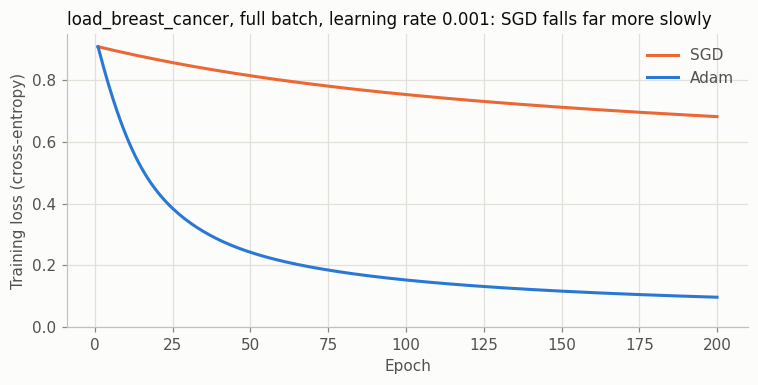

In [10]:
rows = []
for dataset, (prepare, task) in DATASETS.items():
    for solver in ["sgd", "adam"]:
        for learning_rate in [0.001, 0.01, 0.1]:
            rows += [{"Dataset": dataset, "Solver": solver, "Learning rate": learning_rate, **r}
                     for r in run(prepare, task, solver=solver, learning_rate=learning_rate)]
optimizer_table = summarize(rows)
display(optimizer_table["Test"].unstack(["Solver", "Learning rate"]))
print("Runs stopped by the non-finite guard:", int(optimizer_table["Diverged"].sum()))

X_train, _, y_train, _ = prepare_cancer(SEEDS[0])
fig, ax = plt.subplots(figsize=(7, 3.6))
for solver, color, label in [("sgd", SKLEARN, "SGD"), ("adam", MINE, "Adam")]:
    model = SimpleSLPClassifier(solver=solver, batch_size=None, random_state=SEEDS[0]).fit(X_train, y_train)
    plot_curve(ax, model.loss_curve_, color=color, label=label)
ax.set(xlabel="Epoch", ylabel="Training loss (cross-entropy)", ylim=(0, None))
ax.set_title("load_breast_cancer, full batch, learning rate 0.001: SGD falls far more slowly", loc="left", fontsize=11)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

**Reading the results.**

- **Hypothesis checked:** at `learning_rate=0.001`, Adam beats SGD on all four datasets: 0.489 against 0.363 on diabetes, 0.968 against
  0.945 on breast cancer, 0.797 against 0.705 on Titanic, and 0.975 against 0.874 on digits. The figure shows why: with the same number of
  full-batch updates, Adam's loss falls far faster.
- **The learning rate is the real issue for SGD.** With `learning_rate=0.1`, SGD nearly catches up on classification: 0.974 on breast cancer,
  0.797 on Titanic and 0.972 on digits. So the honest conclusion is that SGD needs a larger learning rate, not that it cannot learn.
- **Adam is not always safer.** On classification, it depends little on the learning rate, except that 0.1 costs a little on Titanic and digits.
  On diabetes, however, a larger rate overfits quickly: 0.489 at 0.001, 0.181 at 0.01, and -0.087 at 0.1.
- **No divergence:** the non-finite guard never triggered in these runs.

`solver="adam"` is the default because the provided tests use `learning_rate=0.001` by default, and this is where Adam has the clearest advantage.

### 5.5 Design choice: why the scaffold's initialization was replaced

The scaffold suggests `N(0, 0.01²)`. This cell compares it with the Glorot initialization of `slp_base.py`, on the setting of
the provided `test_constant_output`: a constant target of 5, `learning_rate=0.01`, 100 epochs. The test requires a mean
prediction strictly between 4 and 6, and it draws `X` without a seed.

In [11]:
class SkeletonInitRegressor(SimpleSLPRegressor):
    """Same regressor, with the N(0, 0.01^2) initialization suggested by the scaffold."""

    def _initialize_weights(self, n_features, n_outputs, rng):
        hidden = self.hidden_layer_size
        self.W1_ = rng.normal(0.0, 0.01, size=(n_features, hidden))
        self.b1_ = rng.normal(0.0, 0.01, size=hidden)
        self.W2_ = rng.normal(0.0, 0.01, size=(hidden, n_outputs))
        self.b2_ = rng.normal(0.0, 0.01, size=n_outputs)


rows = []
for name, model_class in [("N(0, 0.01^2)", SkeletonInitRegressor), ("Glorot", SimpleSLPRegressor)]:
    draws = np.random.RandomState(SEEDS[0])
    means = []
    for _ in range(500):
        X_draw = draws.randn(30, 3)
        model = model_class(hidden_layer_size=5, learning_rate=0.01, max_iter=100, random_state=42)
        means.append(model.fit(X_draw, np.full(30, 5.0)).predict(X_draw).mean())
    means = np.array(means)
    rows.append({"Initialization": name, "Test failure rate": np.mean((means <= 4) | (means >= 6)),
                 "Lowest mean prediction": means.min(), "Highest mean prediction": means.max()})
display(pd.DataFrame(rows).round(3))

,Initialization,Test failure rate,Lowest mean prediction,Highest mean prediction
0,"N(0, 0.01^2)",0.162,3.986,4.205
1,Glorot,0.000,4.278,4.594


**Reading the results.** Over these 500 draws, the provided test would fail about one time in six with the scaffold's initialization, and never with
Glorot. A test that fails at random is not acceptable, which justified the change. The exact rate depends on the draws, so it should be read
as an order of magnitude.

## 6. Conclusion

**What is shown.**

- The two classes learn on all five datasets, and the provided tests pass.
- With the same settings, my implementation scores in the same range as scikit-learn on all five datasets. Every gap between the two
  implementations is smaller than the larger of their spreads between seeds.
- Standardization and the learning rate have the largest effects measured here, followed by early stopping on small datasets
  with an oversized network. The batch size mainly affects training speed.

**What the results do not show.**

- The neural network is not always the best choice: the linear baseline ties or beats it on diabetes, breast cancer and iris.
- My defaults are not the best settings for every dataset. They were chosen so that the provided tests pass reliably: ReLU does
  better on Titanic, for example.

**Limits of this report.**

- Five repetitions give only a rough estimate of the spread, and the repeated splits of a dataset are not independent. Gaps smaller than the
  spread between seeds should not be interpreted.
- Test sets are small: 45 samples for iris and 133 for diabetes.
- The Titanic imputation is deliberately simple, and information from `Name`, `Ticket` and `Cabin` is unused. The Kaggle test set has no
  labels, so no score on it is reported.
- The arbitrary-depth bonus is not implemented.